# This is a Jupyter Notebook for Convolutional PTRA

In [7]:
import pandas as pd
import numpy as np
import glob
import os
import ast
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.interpolate import interp1d

# Read the input file

In [8]:
# Input File name
vulnerability_file = "vulnerabilityModel.csv"

# Read CSV file
df_vulnerability = pd.read_csv(vulnerability_file)

IM = df_vulnerability["flow depth [m]"].values
IM = IM[1:]   # if the first value is very small 1e-6

# Show first rows
df_vulnerability.head()


,flow depth [m],16th percentile vulnerability,median vulnerability,84th percentile vulnerability,logarithmic standard deviation,epistemic uncertainty in the median
0,0.000001,0.001355,0.003680,0.009995,0.999276,0.031743
1,0.010000,0.001344,0.003705,0.010215,1.014033,0.058468
2,0.020000,0.001340,0.003736,0.010411,1.024948,0.077940
3,0.030000,0.001327,0.003760,0.010650,1.041168,0.099379
4,0.040000,0.001327,0.003800,0.010885,1.052292,0.117919


# Read the Tsumani Hazard Simulations

In [9]:
# Read hazard curves main file
df_per_hazard_curve = pd.read_csv("FDEC_building_2888.csv")

print(df_per_hazard_curve.head())

IM_hazard = df_per_hazard_curve["FlowDepth"].values

print(IM_hazard.shape)

# Read hazard curves file
hazard_curves = df_per_hazard_curve["FDEC"].values

print(hazard_curves.shape)


   FlowDepth      FDEC
0   0.000000  0.012941
1   0.066422  0.011582
2   0.132843  0.011331
3   0.199265  0.011193
4   0.265686  0.010974
(100,)
(100,)


# Plot Hazard Curves

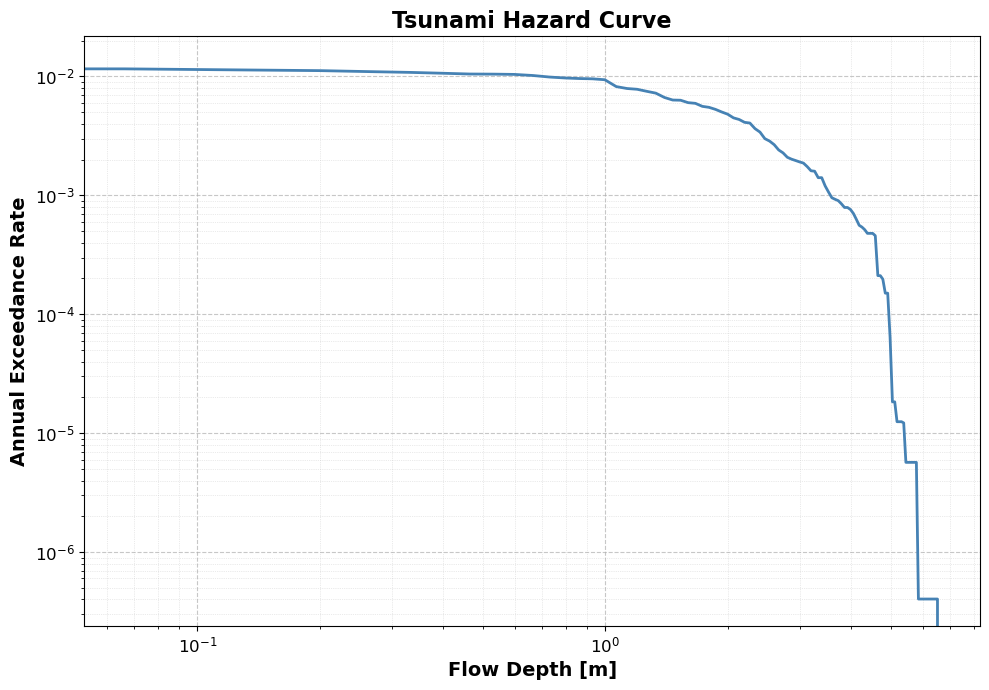

In [10]:
# ---------------------------------------------------
# Create Figure
# ---------------------------------------------------

fig, ax = plt.subplots(figsize=(10,7))


# ---------------------------------------------------
# Plot Hazard Curve
# ---------------------------------------------------

ax.loglog(

    IM_hazard,

    hazard_curves,

    color='steelblue',

    linewidth=2
)


# ---------------------------------------------------
# Labels
# ---------------------------------------------------

ax.set_xlabel(

    "Flow Depth [m]",

    fontsize=14,

    fontweight='bold'
)

ax.set_ylabel(

    "Annual Exceedance Rate",

    fontsize=14,

    fontweight='bold'
)


# ---------------------------------------------------
# Title
# ---------------------------------------------------

ax.set_title(

    "Tsunami Hazard Curve",

    fontsize=16,

    fontweight='bold'
)


# ---------------------------------------------------
# Grid
# ---------------------------------------------------

ax.grid(

    True,

    which='major',

    linestyle='--',

    linewidth=0.8,

    alpha=0.7
)

ax.grid(

    True,

    which='minor',

    linestyle=':',

    linewidth=0.5,

    alpha=0.5
)


# ---------------------------------------------------
# Tick Style
# ---------------------------------------------------

ax.tick_params(

    axis='both',

    which='major',

    labelsize=12
)


# ---------------------------------------------------
# Tight Layout
# ---------------------------------------------------

plt.tight_layout()

plt.show()

# Main Loop for convolving vulnerability and loss λ(LR > lr)=∫ P(LR > lr | IM)·|dλ(IM)|

In [11]:
# =========================================================
# STEP A — Define Loss-Ratio Thresholds
# =========================================================

lr = np.arange(0.01, 1.01, 0.01)


# =========================================================
# STEP B — Read Vulnerability Statistics
# =========================================================

medianLoss_IM = (
    df_vulnerability["median vulnerability"].values
)

medianLoss_IM = medianLoss_IM[1:]


# Logarithmic Mean
ElogLoss_IM = np.log(
    np.maximum(medianLoss_IM,1e-30)
)


# Logarithmic Standard Deviation
siglogLoss_IM = (
    df_vulnerability["logarithmic standard deviation"].values
)

siglogLoss_IM = siglogLoss_IM[1:]


# Avoid zero sigma
siglogLoss_IM = np.maximum(
    siglogLoss_IM,
    1e-6
)


# =========================================================
# STEP C — Construct CCDF Matrix
# =========================================================
#
# G_LR_IM(i,j)
# =
# P(LR > lr_j | IM_i)
#
# =========================================================

G_LR_IM = (

    1
    -
    norm.cdf(

        np.log(lr)[np.newaxis,:],

        ElogLoss_IM[:,np.newaxis],

        siglogLoss_IM[:,np.newaxis]
    )
)

print(
    f"The dimension of the CCDF Matrix is "
    f"{G_LR_IM.shape}"
)


# =========================================================
# STEP D — Read Single Hazard Curve
# =========================================================

lambda_hazard = hazard_curves


# Enforce monotonic decreasing curve
lambda_hazard = np.maximum.accumulate(

    lambda_hazard[::-1]

)[::-1]


# =========================================================
# STEP E — Interpolate Hazard Curve
# =========================================================

dIM = IM[1] - IM[0]


interpHazard = interp1d(

    IM_hazard,

    np.log(
        np.maximum(lambda_hazard,1e-30)
    ),

    kind='linear',

    fill_value='extrapolate'
)


# =========================================================
# STEP F — Differential Hazard
# =========================================================

lambda_IMp = np.exp(

    interpHazard(
        IM + dIM/2
    )
)

lambda_IMm = np.exp(

    interpHazard(
        IM - dIM/2
    )
)


dlambda_IM = np.maximum(

    lambda_IMm - lambda_IMp,

    0
)


# =========================================================
# STEP G — Convolution
# =========================================================

risk_contribution = (

    G_LR_IM
    *
    dlambda_IM[:,np.newaxis]
)


LEC = np.sum(

    risk_contribution,

    axis=0
)


print()

print(
    f"LEC has the shape "
    f"{LEC.shape}"
)


The dimension of the CCDF Matrix is (500, 100)

LEC has the shape (100,)


# Plot Loss Exceedance Curve for all simulations¶

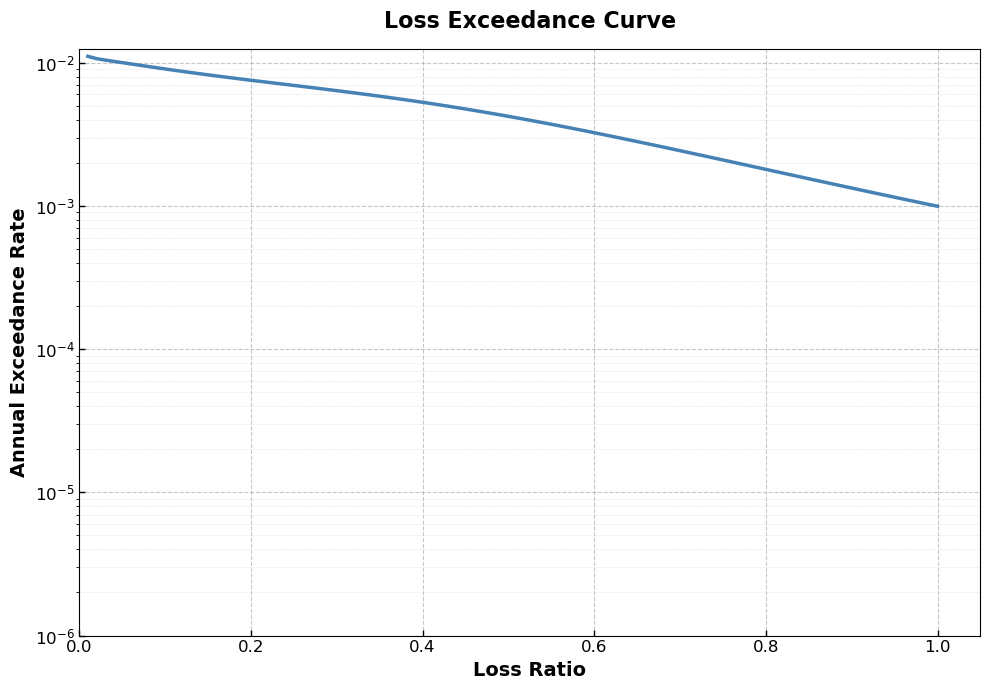

[0.01106404 0.01066407 0.0104208  0.01020631 0.00999895 0.00979533
 0.00959587 0.00940155 0.00921315 0.00903112 0.00885563 0.00868664
 0.00852397 0.00836731 0.00821632 0.0080706  0.00792974 0.00779335
 0.00766101 0.00753232 0.0074069  0.0072844  0.00716445 0.00704673
 0.00693094 0.00681679 0.006704   0.00659235 0.0064816  0.00637157
 0.00626208 0.00615299 0.00604418 0.00593554 0.005827   0.00571852
 0.00561005 0.00550159 0.00539315 0.00528475 0.00517643 0.00506824
 0.00496025 0.00485253 0.00474517 0.00463826 0.00453188 0.00442614
 0.00432114 0.00421696 0.00411372 0.0040115  0.0039104  0.00381051
 0.00371191 0.00361468 0.00351889 0.00342462 0.00333192 0.00324085
 0.00315146 0.0030638  0.0029779  0.0028938  0.00281151 0.00273106
 0.00265247 0.00257574 0.00250088 0.00242788 0.00235674 0.00228746
 0.00222003 0.00215441 0.00209061 0.00202859 0.00196834 0.00190981
 0.001853   0.00179787 0.00174438 0.0016925  0.00164221 0.00159346
 0.00154621 0.00150044 0.00145611 0.00141318 0.00137161 0.0013

In [12]:
# -----------------------------------
# Create Figure
# -----------------------------------

fig, ax = plt.subplots(figsize=(10,7))


# -----------------------------------
# Plot Loss Exceedance Curve
# -----------------------------------

ax.semilogy(

    lr,

    LEC,

    linewidth=2.5,

    color='steelblue'
)


# -----------------------------------
# Labels
# -----------------------------------

ax.set_xlabel(

    "Loss Ratio",

    fontsize=14,

    fontweight='bold'
)

ax.set_ylabel(

    "Annual Exceedance Rate",

    fontsize=14,

    fontweight='bold'
)


# -----------------------------------
# Title
# -----------------------------------

ax.set_title(

    "Loss Exceedance Curve",

    fontsize=16,

    fontweight='bold',

    pad=15
)


# -----------------------------------
# Grid
# -----------------------------------

ax.grid(

    True,

    which='major',

    linestyle='--',

    linewidth=0.8,

    alpha=0.7
)

ax.grid(

    True,

    which='minor',

    linestyle=':',

    linewidth=0.5,

    alpha=0.5
)


# -----------------------------------
# Tick Style
# -----------------------------------

ax.tick_params(

    axis='both',

    which='major',

    labelsize=12,

    direction='in',

    length=4,

    width=1.0
)


# -----------------------------------
# Axis Limits
# -----------------------------------

ax.set_xlim(left=0)

ax.set_ylim(bottom=1e-6)


# -----------------------------------
# Tight Layout
# -----------------------------------

plt.tight_layout()

plt.show()


print(LEC)

# Read the LEC from the simulation m,ethod

In [13]:
# Read saved LEC file
df_LEC = pd.read_csv("LEC_building_2888.csv")

# Show first rows
print(df_LEC.head())

# Extract vectors
loss_values = df_LEC["Loss"].values

loss_values = loss_values/131518.102052793
LEC_sim = df_LEC["LEC"].values

print()
print(f"loss_values shape = {loss_values.shape}")
print(f"LEC_sim shape = {LEC_sim.shape}")

print(loss_values)

print(loss_values.min(), loss_values.max())
print(LEC_sim.min(), LEC_sim.max())

print(lr.min(), lr.max())
print(LEC.min(), LEC.max())

          Loss       LEC
0     0.000000  0.023950
1  1326.128717  0.010422
2  2652.257434  0.010336
3  3978.386151  0.009945
4  5304.514867  0.009885

loss_values shape = (100,)
LEC_sim shape = (100,)
[0.         0.01008324 0.02016648 0.03024972 0.04033296 0.0504162
 0.06049945 0.07058269 0.08066593 0.09074917 0.10083241 0.11091565
 0.12099889 0.13108213 0.14116537 0.15124861 0.16133186 0.1714151
 0.18149834 0.19158158 0.20166482 0.21174806 0.2218313  0.23191454
 0.24199778 0.25208102 0.26216427 0.27224751 0.28233075 0.29241399
 0.30249723 0.31258047 0.32266371 0.33274695 0.34283019 0.35291343
 0.36299668 0.37307992 0.38316316 0.3932464  0.40332964 0.41341288
 0.42349612 0.43357936 0.4436626  0.45374584 0.46382909 0.47391233
 0.48399557 0.49407881 0.50416205 0.51424529 0.52432853 0.53441177
 0.54449501 0.55457825 0.5646615  0.57474474 0.58482798 0.59491122
 0.60499446 0.6150777  0.62516094 0.63524418 0.64532742 0.65541066
 0.66549391 0.67557715 0.68566039 0.69574363 0.70582687 0.715910

# Plot Loss Exceedance Curve for all simulations¶

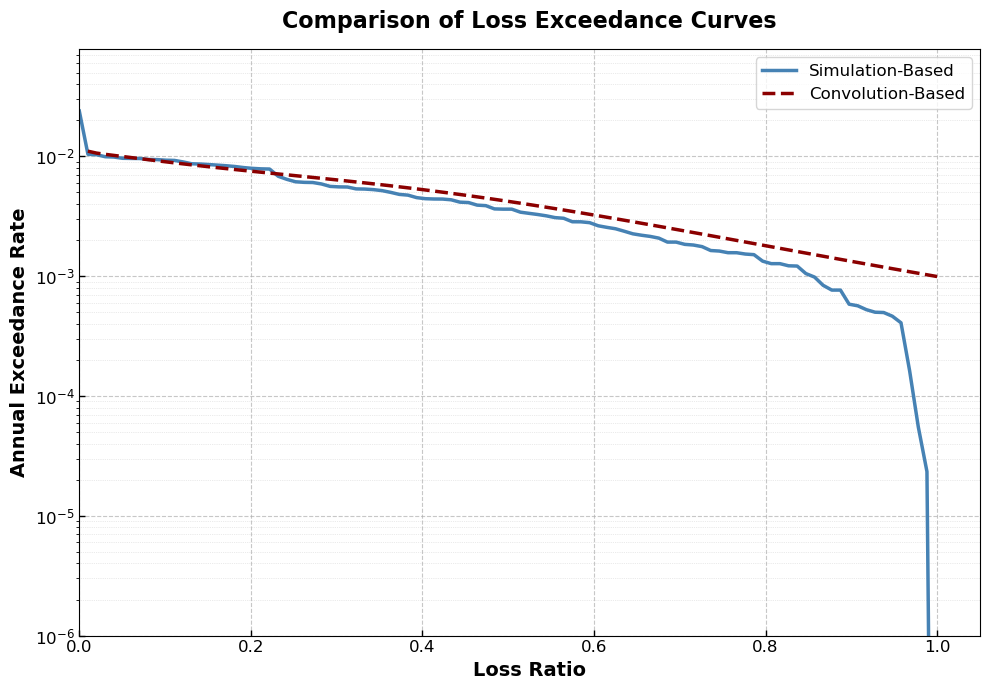

In [15]:
# ---------------------------------------------------
# Create Figure
# ---------------------------------------------------

fig, ax = plt.subplots(figsize=(10,7))


# ---------------------------------------------------
# Plot Simulation-Based LEC
# ---------------------------------------------------

ax.semilogy(

    loss_values,

    np.maximum(LEC_sim,1e-12),

    linewidth=2.5,

    color='steelblue',

    label='Simulation-Based'
)


# ---------------------------------------------------
# Plot Convolution-Based LEC
# ---------------------------------------------------

ax.semilogy(

    lr,

    np.maximum(LEC,1e-12),

    linewidth=2.5,

    color='darkred',

    linestyle='--',

    label='Convolution-Based'
)


# ---------------------------------------------------
# Labels
# ---------------------------------------------------

ax.set_xlabel(

    "Loss Ratio",

    fontsize=14,

    fontweight='bold'
)

ax.set_ylabel(

    "Annual Exceedance Rate",

    fontsize=14,

    fontweight='bold'
)


# ---------------------------------------------------
# Title
# ---------------------------------------------------

ax.set_title(

    "Comparison of Loss Exceedance Curves",

    fontsize=16,

    fontweight='bold',

    pad=15
)


# ---------------------------------------------------
# Grid
# ---------------------------------------------------

ax.grid(

    True,

    which='major',

    linestyle='--',

    linewidth=0.8,

    alpha=0.7
)

ax.grid(

    True,

    which='minor',

    linestyle=':',

    linewidth=0.5,

    alpha=0.5
)


# ---------------------------------------------------
# Tick Style
# ---------------------------------------------------

ax.tick_params(

    axis='both',

    which='major',

    labelsize=12,

    direction='in',

    length=4,

    width=1.0
)


# ---------------------------------------------------
# Axis Limits
# ---------------------------------------------------

ax.set_xlim(left=0)

ax.set_ylim(bottom=1e-6)


# ---------------------------------------------------
# Legend
# ---------------------------------------------------

ax.legend(fontsize=12)


# ---------------------------------------------------
# Tight Layout
# ---------------------------------------------------

plt.tight_layout()
plt.savefig(
    "comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()